# New characterization experiments

Score ablation, baseline dependence, and exploratory associations with sample size and class structure.

Reuse the main functions to reproduce the main paper structure for the additional experiments. 

# Main structure

In [1]:
# =========================
# 0. Imports and setup
# =========================

from pathlib import Path
import sys
import random
import time
import warnings


import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy, skew, kurtosis, zscore, kruskal, f_oneway
from scipy.spatial.distance import jensenshannon

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, f1_score
from sklearn.feature_selection import mutual_info_classif, chi2

random.seed(42)
np.random.seed(42)

import json, platform, scipy, sklearn
from scipy.stats import spearmanr
from IPython.display import display


## Dataset pool preparation 

In [2]:
# =========================
# 1. Project root and datasets
# =========================

from pathlib import Path
import sys

def find_project_root(start: Path, marker="core"):
    for parent in [start] + list(start.parents):
        if (parent / marker).exists():
            return parent
    return start

PROJECT_ROOT = find_project_root(Path.cwd())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

random.seed(42)
data_path = PROJECT_ROOT / "data"

datasets = {
    "abalone": data_path / "abalone.csv",
    "anneal": data_path / "anneal.csv",
    "arrhythmia": data_path / "arrhythmia.csv",
    "bridges": data_path / "bridges_version1.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "car": data_path / "car.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
    "glass": data_path / "glass.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "ionosphere": data_path / "ionosphere.csv",
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "wine_red": data_path / "winequality_red.csv",
    "iris": data_path / "iris.csv",
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
}

# Edit this list to only include the datasets to analyse
selected_dataset_names = list(datasets.keys())
datasets = {name: path for name, path in datasets.items() if name in selected_dataset_names}

print("Project root:", PROJECT_ROOT)
print("Data path:", data_path)
print("Datasets selected:", list(datasets.keys()))


Project root: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees
Data path: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\data
Datasets selected: ['abalone', 'anneal', 'arrhythmia', 'bridges', 'balance_scale', 'car', 'cylinder_bands', 'glass', 'heart_disease', 'ionosphere', 'semeion', 'sonar', 'tic_tac_toe', 'breast_cancer', 'wine_red', 'iris', 'haberman', 'parkinsons', 'banknote', 'credit_approval']


In [3]:
# =========================
# 2. Target configuration and loader
# =========================

# Explicit target/ID handling. Values may be column names, integer positions, or
# an ordered list of fallbacks. This prevents accidental target leakage or
# target-column mistakes when the label is not the final column.
TARGET_CONFIG = {'abalone': 'target',
 'anneal': 'target',
 'arrhythmia': 'target',
 'bridges': 'target',
 'balance_scale': ['class', 'Class', 'balance', 'Balance', 0],
 'car': 'target',
 'cylinder_bands': 'target',
 'glass': 'target',
 'heart_disease': '13',
 'ionosphere': '34',
 'semeion': 'target',
 'sonar': '60',
 'tic_tac_toe': '9',
 'breast_cancer': 'target',
 'wine_red': 'target',
 'iris': 'target',
 'haberman': '3',
 'parkinsons': ['status', 'Status'],
 'banknote': '4',
 'credit_approval': '15'}

# Empty lists explicitly mean no remaining known ID columns.
# Bridges/glass IDs were removed during CSV curation.
ID_COLUMNS = {'abalone': [],
 'anneal': [],
 'arrhythmia': [],
 'bridges': [],
 'balance_scale': [],
 'car': [],
 'cylinder_bands': ['feature_001'],
 'glass': [],
 'heart_disease': [],
 'ionosphere': [],
 'semeion': [],
 'sonar': [],
 'tic_tac_toe': [],
 'breast_cancer': [],
 'wine_red': [],
 'iris': [],
 'haberman': [],
 'parkinsons': [['name', 'Name']],
 'banknote': [],
 'credit_approval': []}

MISSING_TOKENS = ["?", "NA", "N/A", "na", "n/a", "", " ", "null", "None"]


def _resolve_column(df, spec, dataset_name, purpose):
    """Resolve a column spec that can be a name, integer position, or fallback list."""
    specs = spec if isinstance(spec, (list, tuple)) else [spec]

    for candidate in specs:
        if isinstance(candidate, int):
            if -len(df.columns) <= candidate < len(df.columns):
                return df.columns[candidate]
        elif candidate in df.columns:
            return candidate

    available = list(df.columns)
    raise ValueError(
        f"Could not resolve {purpose} for {dataset_name}. "
        f"Tried {specs}; available columns: {available}"
    )


def _resolve_existing_columns(df, specs):
    """Return only the configured columns that exist in this concrete CSV."""
    resolved = []
    for spec in specs:
        try:
            col = _resolve_column(df, spec, "dataset", "ID column")
            if col not in resolved:
                resolved.append(col)
        except ValueError as exc:
            raise ValueError("Configured identifier is missing") from exc
    return resolved


def load_dataset(name, path):
    # Load a CSV and split into X and y.
    df = pd.read_csv(path, na_values=MISSING_TOKENS)
    df.columns = [str(c).strip() for c in df.columns]

    if name not in TARGET_CONFIG or name not in ID_COLUMNS:
        raise ValueError(f"Missing explicit target/ID configuration for {name}")
    target_spec = TARGET_CONFIG[name]
    target_col = _resolve_column(df, target_spec, name, "target column")

    id_cols = _resolve_existing_columns(df, ID_COLUMNS[name])
    id_cols = [c for c in id_cols if c != target_col]

    X = df.drop(columns=[target_col] + id_cols).copy()
    y = df[target_col].copy()

    valid_target = ~y.isna()
    X = X.loc[valid_target].reset_index(drop=True)
    y = y.loc[valid_target].reset_index(drop=True)

    y_encoded = LabelEncoder().fit_transform(y.astype(str))

    return {
        "df": df,
        "X": X,
        "y": y_encoded,
        "y_raw": y,
        "target_col": target_col,
        "dropped_id_cols": id_cols,
    }


loaded = {}
target_audit_rows = []

for name, path in datasets.items():
    try:
        obj = load_dataset(name, path)
        loaded[name] = obj
        y_raw = obj["y_raw"]

        target_audit_rows.append({
            "dataset": name,
            "target_col": obj["target_col"],
            "dropped_id_cols": ", ".join(obj["dropped_id_cols"]),
            "n_samples": obj["X"].shape[0],
            "n_features": obj["X"].shape[1],
            "n_classes": pd.Series(obj["y"]).nunique(),
            "min_class_count": pd.Series(obj["y"]).value_counts().min(),
            "class_counts_raw": json.dumps({str(k): int(v) for k, v in y_raw.value_counts().sort_index().items()}),
            "n_missing_targets_removed": int(obj["df"][obj["target_col"]].isna().sum()),
        })

        print(
            f"Loaded {name}: {obj['X'].shape[0]} rows, {obj['X'].shape[1]} features, "
            f"target='{obj['target_col']}', dropped_id_cols={obj['dropped_id_cols']}"
        )
    except Exception as e:
        raise ValueError(f"Could not load {name}: {e}") from e

target_audit_df = pd.DataFrame(target_audit_rows).sort_values("dataset")
target_audit_df


Loaded abalone: 4177 rows, 8 features, target='target', dropped_id_cols=[]
Loaded anneal: 798 rows, 38 features, target='target', dropped_id_cols=[]
Loaded arrhythmia: 452 rows, 279 features, target='target', dropped_id_cols=[]
Loaded bridges: 108 rows, 11 features, target='target', dropped_id_cols=[]
Loaded balance_scale: 625 rows, 4 features, target='class', dropped_id_cols=[]
Loaded car: 1728 rows, 6 features, target='target', dropped_id_cols=[]
Loaded cylinder_bands: 540 rows, 38 features, target='target', dropped_id_cols=['feature_001']
Loaded glass: 214 rows, 9 features, target='target', dropped_id_cols=[]
Loaded heart_disease: 303 rows, 13 features, target='13', dropped_id_cols=[]
Loaded ionosphere: 351 rows, 34 features, target='34', dropped_id_cols=[]
Loaded semeion: 1593 rows, 256 features, target='target', dropped_id_cols=[]
Loaded sonar: 208 rows, 60 features, target='60', dropped_id_cols=[]
Loaded tic_tac_toe: 958 rows, 9 features, target='9', dropped_id_cols=[]
Loaded bre

In [4]:
# PAPER-DEFINED: fail before any baseline or statistical analysis.
assert set(datasets) <= set(TARGET_CONFIG), "Every selected dataset needs a target"
assert set(loaded) == set(datasets), "Dataset loading was incomplete"
for name, obj in loaded.items():
    assert obj['X'].columns.is_unique, f"{name}: duplicate predictors"
    assert obj['target_col'] not in obj['X'], f"{name}: target leakage"
    assert len(obj['y']) > 0 and len(np.unique(obj['y'])) >= 2, f"{name}: invalid target"
    assert obj['X'].shape[1] > 0, f"{name}: no predictors"
    assert not obj['y_raw'].isna().any(), f"{name}: missing target after filtering"
    assert not set(obj['dropped_id_cols']) & set(obj['X']), f"{name}: ID leakage"
if 'parkinsons' in loaded:
    p = loaded['parkinsons']
    assert p['target_col'].lower() == 'status' and p['dropped_id_cols'] == ['name']
    assert p['X'].shape == (195, 22) and len(np.unique(p['y'])) == 2
    assert np.bincount(p['y']).min() == 48, "Unexpected Parkinsons class counts"
EXPERIMENT_ROOT = PROJECT_ROOT / 'results' / 'new_characterization_experiments'
output_dir = EXPERIMENT_ROOT / 'tables'
(EXPERIMENT_ROOT / 'figures').mkdir(parents=True, exist_ok=True)
(EXPERIMENT_ROOT / 'cache').mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)
target_audit_df.to_csv(output_dir / 'target_audit.csv', index=False)
display(target_audit_df)


,dataset,target_col,dropped_id_cols,n_samples,n_features,n_classes,min_class_count,class_counts_raw,n_missing_targets_removed
0,abalone,target,,4177,8,28,1,"{""0"": 1, ""1"": 634, ""2"": 487, ""3"": 267, ""4"": 20...",0
1,anneal,target,,798,38,5,8,"{""0"": 8, ""1"": 88, ""2"": 608, ""3"": 60, ""4"": 34}",0
2,arrhythmia,target,,452,279,13,2,"{""0.0"": 245, ""1.0"": 50, ""2.0"": 4, ""3.0"": 5, ""4...",0
4,balance_scale,class,,625,4,3,49,"{""B"": 49, ""L"": 288, ""R"": 288}",0
18,banknote,4,,1372,4,2,610,"{""0"": 762, ""1"": 610}",0
13,breast_cancer,target,,569,30,2,212,"{""0.0"": 212, ""1.0"": 357}",0
3,bridges,target,,108,11,8,1,"{""0"": 13, ""1"": 11, ""2"": 10, ""3"": 1, ""4"": 44, ""...",0
5,car,target,,1728,6,4,65,"{""0"": 384, ""1"": 69, ""2"": 1210, ""3"": 65}",0
19,credit_approval,15,,690,15,2,307,"{""+"": 307, ""-"": 383}",0
6,cylinder_bands,target,feature_001,540,38,2,228,"{""0"": 228, ""2"": 312}",0


## Baseline performance and dataset difficulty dimensions

Baselines use macro-F1 under the same repeated stratified 5-fold protocol.

The dataset characterization is explicitly separated into three dimensions:

1. **Predictive difficulty**: low baseline macro-F1 plus high within-model CV instability.
2. **Strategy sensitivity**: disagreement between baseline algorithms.
3. **Computational burden**: runtime and tree-size/complexity indicators.

The primary Easy/Intermediate/Hard label is based only on predictive difficulty. Model spread, tree size, and runtime remain available as complementary experimental-profile descriptors, and never enter the main difficulty category.


In [5]:
def build_preprocessor(X, for_linear=False):
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if for_linear:
        numeric_steps.append(("scaler", StandardScaler()))

    # Use sparse_output when available; fall back for older scikit-learn.
    try:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

    transformers = []
    if numeric_cols:
        transformers.append(("num", Pipeline(numeric_steps), numeric_cols))
    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", onehot),
            ]),
            categorical_cols,
        ))

    return ColumnTransformer(transformers, remainder="drop")


# PAPER-DEFINED common protocol. Runtime = elapsed seconds for all 15 CV fits
# and scores for a strategy (including pipeline and scheduling overhead).
CV_N_SPLITS, CV_N_REPEATS, CV_RANDOM_STATE = 5, 3, 42
N_JOBS = 1  # serial execution makes warning capture and timing auditable
NON_DUMMY_BASELINE_MODELS = ['decision_tree_default', 'decision_tree_balanced',
                            'logistic_regression', 'logistic_regression_balanced']
TREE_BASELINE_MODELS = NON_DUMMY_BASELINE_MODELS[:2]
DUMMY_REFERENCE_MODELS = ['dummy_most_frequent', 'dummy_stratified']
TREE_CONFIG = dict(criterion='gini', splitter='best', max_depth=None,
                   min_samples_split=2, min_samples_leaf=1, max_features=None,
                   min_weight_fraction_leaf=0.0, max_leaf_nodes=None,
                   min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0,
                   random_state=42)
LR_CONFIG = dict(penalty='l2', C=1.0, solver='lbfgs', max_iter=5000,
                 tol=1e-4, class_weight=None, random_state=42, fit_intercept=True)
MODEL_CONFIGS = {
    'decision_tree_default': TREE_CONFIG,
    'decision_tree_balanced': {**TREE_CONFIG, 'class_weight': 'balanced'},
    'logistic_regression': LR_CONFIG,
    'logistic_regression_balanced': {**LR_CONFIG, 'class_weight': 'balanced'},
    'dummy_most_frequent': dict(strategy='most_frequent', random_state=42),
    'dummy_stratified': dict(strategy='stratified', random_state=42),
}
def make_baseline(name, X):
    config = MODEL_CONFIGS[name]
    if name in DUMMY_REFERENCE_MODELS:
        return DummyClassifier(**config)
    linear = name.startswith('logistic')
    estimator = LogisticRegression(**config) if linear else DecisionTreeClassifier(**config)
    return Pipeline([('preprocess', build_preprocessor(X, for_linear=linear)),
                     ('model', estimator)])

def evaluate_baselines(data, cv_seed=42, include_dummy=True, models=None):
    from sklearn.model_selection import RepeatedStratifiedKFold
    rows, audits = [], []
    if cv_seed != CV_RANDOM_STATE:
        raise ValueError('This experiment fixes the CV seed at 42')
    models = list(models) if models is not None else NON_DUMMY_BASELINE_MODELS + (DUMMY_REFERENCE_MODELS if include_dummy else [])
    if not models or len(models) != len(set(models)) or not set(models) <= set(MODEL_CONFIGS):
        raise ValueError('Models must be explicit, unique and configured')
    for name, obj in data.items():
        X, y = obj['X'], obj['y']
        minimum = int(np.bincount(y).min())
        eligible = minimum >= CV_N_SPLITS
        issue = '' if eligible else f'min_class_count={minimum} < 5'
        audits.append(dict(dataset=name, min_class_count=minimum, comparable_cv=eligible,
                           cv_issue=issue, cv_n_splits=5, cv_n_repeats=3, cv_seed=cv_seed))
        if data_digest(obj) != experiment_store.identities[name]['filtered_data_sha256']:
            raise ValueError(f'{name}: data changed after split materialization')
        splits = experiment_store.splits[name]
        for model_name in models:
            row = dict(dataset=name, model=model_name, cv_seed=cv_seed, cv_folds=5,
                cv_repeats=3, n_scores=0, scores=[], error=issue, warnings='',
                f1_macro_mean=np.nan, f1_macro_std=np.nan, f1_macro_min=np.nan,
                f1_macro_max=np.nan, runtime_seconds=np.nan, mean_tree_nodes=np.nan,
                mean_tree_depth=np.nan, mean_tree_leaves=np.nan,
                tree_nodes=[], tree_depths=[], tree_leaves=[])
            caught = []
            if eligible:
                estimator = make_baseline(model_name, X)
                is_tree = isinstance(estimator, Pipeline) and isinstance(estimator.named_steps['model'], DecisionTreeClassifier)
                signature, spec = experiment_store.signature(name, model_name, estimator, N_JOBS)
                cached = experiment_store.read(name, model_name, signature)
                if cached is not None:
                    rows.append(cached)
                    continue
                try:
                    start = time.perf_counter()
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter('always')
                        result = cross_validate(estimator, X, y,
                            cv=splits, scoring=make_scorer(f1_score, average='macro', zero_division=0),
                            n_jobs=N_JOBS, error_score='raise',
                            return_estimator=is_tree)
                    scores = result['test_score']
                    assert len(scores) == 15 and np.isfinite(scores).all(), 'Invalid CV scores'
                    row.update(n_scores=len(scores), scores=scores.tolist(),
                        f1_macro_mean=scores.mean(), f1_macro_std=scores.std(ddof=1),
                        f1_macro_min=scores.min(), f1_macro_max=scores.max(),
                        runtime_seconds=time.perf_counter()-start)
                    if is_tree:
                        trees = [e.named_steps['model'].tree_ for e in result['estimator']]
                        row.update(tree_nodes=[int(t.node_count) for t in trees],
                            tree_depths=[int(t.max_depth) for t in trees],
                            tree_leaves=[int(t.n_leaves) for t in trees])
                        row.update(mean_tree_nodes=np.mean([t.node_count for t in trees]),
                            mean_tree_depth=np.mean([t.max_depth for t in trees]),
                            mean_tree_leaves=np.mean([t.n_leaves for t in trees]))
                except Exception as exc:
                    row['error'] = repr(exc)
                    print(f'[FIT ERROR] {name}/{model_name}: {exc}')
                row['warnings'] = '\n'.join(sorted({f'{w.category.__name__}: {w.message}' for w in caught}))
                if row['warnings']:
                    print(f'[WARNINGS] {name}/{model_name}: {row["warnings"][:300]}')
            if eligible:
                experiment_store.save(row, signature, spec)
            rows.append(row)
        print(f'CV seed {cv_seed}: {name} completed; comparable={eligible}')
    return pd.DataFrame(rows), pd.DataFrame(audits)

def successful_rows(frame):
    return (frame['error'].fillna('').eq('') & frame['n_scores'].eq(15)
            & frame['scores'].map(lambda s: len(s) == 15 and np.isfinite(s).all())
            & frame[['f1_macro_mean', 'f1_macro_std']].notna().all(axis=1))

def aggregate_baselines(frame, audit, required_models=None):
    required_models = list(NON_DUMMY_BASELINE_MODELS if required_models is None else required_models)
    if not required_models or len(set(required_models)) != len(required_models) or set(required_models) & set(DUMMY_REFERENCE_MODELS):
        raise ValueError('A panel requires unique non-dummy models')
    selected = frame[frame.model.isin(required_models)]
    if selected.duplicated(['dataset', 'model']).any():
        raise ValueError('Duplicate dataset/model evaluations')
    if not selected.cv_seed.eq(42).all() or not selected.cv_folds.eq(5).all() or not selected.cv_repeats.eq(3).all():
        raise ValueError('Mixed CV protocols')
    good = frame.loc[successful_rows(frame) & frame.model.isin(required_models)]
    agg = good.groupby('dataset').agg(n_successful_non_dummy_models=('model','nunique'),
        baseline_macro_f1_mean=('f1_macro_mean','mean'),
        baseline_macro_f1_best=('f1_macro_mean','max'),
        baseline_macro_f1_worst=('f1_macro_mean','min'),
        mean_model_cv_f1_std=('f1_macro_std','mean')).reset_index()
    agg = audit.merge(agg, on='dataset', how='left', validate='one_to_one')
    complete = frame[frame.model.isin(required_models)].groupby('dataset').apply(
        lambda g: len(g) == len(required_models) and set(g.model) == set(required_models)
        and successful_rows(g).all())
    agg['complete_non_dummy_protocol'] = agg.dataset.map(complete).fillna(False).astype(bool)
    agg['ranking_eligible'] = (agg.comparable_cv & agg.min_class_count.ge(5)
        & agg.complete_non_dummy_protocol
        & agg[['baseline_macro_f1_mean','mean_model_cv_f1_std']].notna().all(axis=1))
    agg['ranking_exclusion_reason'] = agg.apply(lambda r: '' if r.ranking_eligible else
        (r.cv_issue or 'Incomplete required-model protocol: inspect baseline_results.csv errors and score counts'), axis=1)
    # Partial models remain in baseline_df for inspection, never canonical aggregates.
    agg.loc[~agg.ranking_eligible, ['baseline_macro_f1_mean','baseline_macro_f1_best',
        'baseline_macro_f1_worst','mean_model_cv_f1_std']] = np.nan
    agg['baseline_macro_f1_spread'] = agg.baseline_macro_f1_best - agg.baseline_macro_f1_worst
    agg['cv_variability'] = agg.mean_model_cv_f1_std
    dummy = frame.loc[successful_rows(frame) & frame.model.isin(DUMMY_REFERENCE_MODELS)]
    agg['best_dummy_macro_f1'] = agg.dataset.map(dummy.groupby('dataset').f1_macro_mean.max())
    agg['baseline_gain_over_dummy'] = agg.baseline_macro_f1_mean - agg.best_dummy_macro_f1
    return agg

# Cache must be initialized before the canonical evaluation, so Run All can reuse it.
from experiments.characterization_persistence import ExperimentStore, data_digest, validate_evaluations, write_json
experiment_store = ExperimentStore(EXPERIMENT_ROOT, loaded, datasets,
    [load_dataset, _resolve_column, _resolve_existing_columns, build_preprocessor, make_baseline, evaluate_baselines],
    TARGET_CONFIG, ID_COLUMNS, MISSING_TOKENS)
baseline_df, cv_audit_df = evaluate_baselines(loaded)
experiment_store.export(baseline_df, 'baseline')
cv_audit_df.to_csv(output_dir / 'baseline_cv_audit.csv', index=False)
write_json(EXPERIMENT_ROOT / 'canonical_model_configuration.json', MODEL_CONFIGS)
baseline_characteristics_df = aggregate_baselines(baseline_df, cv_audit_df)
display(baseline_characteristics_df)


CV seed 42: abalone completed; comparable=False
CV seed 42: anneal completed; comparable=True
CV seed 42: arrhythmia completed; comparable=False
CV seed 42: bridges completed; comparable=False
CV seed 42: balance_scale completed; comparable=True
CV seed 42: car completed; comparable=True
CV seed 42: cylinder_bands completed; comparable=True
CV seed 42: glass completed; comparable=True
CV seed 42: heart_disease completed; comparable=True
CV seed 42: ionosphere completed; comparable=True
CV seed 42: semeion completed; comparable=True
CV seed 42: sonar completed; comparable=True
CV seed 42: tic_tac_toe completed; comparable=True
CV seed 42: breast_cancer completed; comparable=True
CV seed 42: wine_red completed; comparable=True
CV seed 42: iris completed; comparable=True
CV seed 42: haberman completed; comparable=True
CV seed 42: parkinsons completed; comparable=True
CV seed 42: banknote completed; comparable=True
CV seed 42: credit_approval completed; comparable=True
characterization_cel

,dataset,min_class_count,comparable_cv,cv_issue,cv_n_splits,cv_n_repeats,cv_seed,n_successful_non_dummy_models,baseline_macro_f1_mean,baseline_macro_f1_best,baseline_macro_f1_worst,mean_model_cv_f1_std,complete_non_dummy_protocol,ranking_eligible,ranking_exclusion_reason,baseline_macro_f1_spread,cv_variability,best_dummy_macro_f1,baseline_gain_over_dummy
0,abalone,1,False,min_class_count=1 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=1 < 5,NaN,NaN,NaN,NaN
1,anneal,8,True,,5,3,42,4.0,0.789505,0.907593,0.619586,0.068259,True,True,,0.288007,0.068259,0.201713,0.587792
2,arrhythmia,2,False,min_class_count=2 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=2 < 5,NaN,NaN,NaN,NaN
3,bridges,1,False,min_class_count=1 < 5,5,3,42,NaN,NaN,NaN,NaN,NaN,False,False,min_class_count=1 < 5,NaN,NaN,NaN,NaN
4,balance_scale,49,True,,5,3,42,4.0,0.655328,0.853269,0.582401,0.022737,True,True,,0.270867,0.022737,0.329519,0.325809
5,car,65,True,,5,3,42,4.0,0.865277,0.932889,0.778695,0.032038,True,True,,0.154194,0.032038,0.245868,0.619409
6,cylinder_bands,228,True,,5,3,42,4.0,0.748637,0.763512,0.738771,0.054268,True,True,,0.024741,0.054268,0.494167,0.254470
7,glass,9,True,,5,3,42,4.0,0.621593,0.656832,0.539585,0.083331,True,True,,0.117247,0.083331,0.114581,0.507012
8,heart_disease,13,True,,5,3,42,4.0,0.300365,0.333069,0.238225,0.056310,True,True,,0.094844,0.056310,0.182116,0.118248
9,ionosphere,126,True,,5,3,42,4.0,0.871518,0.883384,0.862892,0.040564,True,True,,0.020492,0.040564,0.504045,0.367474


## Calculation of necessary inputs for score

In [6]:
# PAPER-DEFINED computational inputs, calculated once.
computational_source_df = baseline_df.loc[successful_rows(baseline_df)
    & baseline_df.model.isin(NON_DUMMY_BASELINE_MODELS)]
runtime_df = computational_source_df.groupby('dataset').agg(
    baseline_runtime_seconds_mean=('runtime_seconds','mean')).reset_index()
tree_complexity_df = computational_source_df.loc[
    computational_source_df.model.isin(TREE_BASELINE_MODELS)].groupby('dataset').agg(
    mean_tree_nodes=('mean_tree_nodes','mean'), mean_tree_depth=('mean_tree_depth','mean'),
    mean_tree_leaves=('mean_tree_leaves','mean')).reset_index()
computational_characteristics_df = pd.DataFrame({'dataset': list(loaded)}).merge(
    runtime_df, on='dataset', how='left').merge(tree_complexity_df, on='dataset', how='left')
display(computational_characteristics_df)

,dataset,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves
0,abalone,NaN,NaN,NaN,NaN
1,anneal,0.480122,130.133333,18.600000,65.566667
2,arrhythmia,NaN,NaN,NaN,NaN
3,bridges,NaN,NaN,NaN,NaN
4,balance_scale,0.078227,262.866667,11.333333,131.933333
5,car,0.240828,211.133333,13.533333,106.066667
6,cylinder_bands,0.449672,127.200000,13.566667,64.100000
7,glass,0.096240,83.666667,10.500000,42.333333
8,heart_disease,0.097229,167.533333,11.833333,84.266667
9,ionosphere,0.228086,44.400000,8.766667,22.700000


In [7]:
# Multi-dimensional dataset profile
# =====================================
# Paper-aligned implementation of Sections 3.3 and 3.4.
#
# Assumptions from upstream cells:
# - baseline_macro_f1_mean = F_d, mean macro-F1 across NON-DUMMY baselines.
# - mean_model_cv_f1_std = V_d, mean within-model CV std across NON-DUMMY baselines.
# - baseline_macro_f1_spread = S_d, range of model-level mean macro-F1 across NON-DUMMY baselines.
# - the target/eligibility audit (min class count >= k=5) was already applied before baseline evaluation.


def minmax_normalize_on_pool(series, pool_mask):
    """Min-max normalize using only the eligible benchmark pool."""
    values = pd.to_numeric(series, errors="coerce")
    pool_mask = pd.Series(pool_mask, index=values.index).fillna(False).astype(bool)

    result = pd.Series(np.nan, index=values.index, dtype=float)
    valid = pool_mask & values.notna()

    if valid.sum() == 0:
        return result

    min_val = values.loc[valid].min()
    max_val = values.loc[valid].max()

    if max_val == min_val:
        result.loc[valid] = 0.0
        return result

    result.loc[valid] = (
        values.loc[valid] - min_val
    ) / (
        max_val - min_val
    )

    return result


# ------------------------------------------------------------------
# Base dataset-level profile
# ------------------------------------------------------------------

dataset_profile_df = baseline_characteristics_df.copy()

# Eligibility was established from all four complete model evaluations.

# ============================================================
# 1. Predictive difficulty
# ============================================================
#
# F_d = mean macro-F1 across non-dummy baseline strategies
# E_d = 1 - F_d
# V_d = mean within-model cross-validation variability
#
# D_pred_d = 0.70 * z(E_d) + 0.30 * z(V_d)


dataset_profile_df["predictive_error"] = (
    1.0 - dataset_profile_df["baseline_macro_f1_mean"]
)

dataset_profile_df["cv_variability"] = (
    dataset_profile_df["mean_model_cv_f1_std"]
)

dataset_profile_df["predictive_error_score"] = minmax_normalize_on_pool(
    dataset_profile_df["predictive_error"],
    dataset_profile_df["ranking_eligible"],
)

dataset_profile_df["cv_variability_score"] = minmax_normalize_on_pool(
    dataset_profile_df["cv_variability"],
    dataset_profile_df["ranking_eligible"],
)

dataset_profile_df["predictive_difficulty_score"] = (
    0.70 * dataset_profile_df["predictive_error_score"]
    + 0.30 * dataset_profile_df["cv_variability_score"]
)


# ============================================================
# 2. Strategy sensitivity
# ============================================================
#
# S_d = max_m(mu_d,m) - min_m(mu_d,m)
#
# This is a complementary descriptor. It does NOT modify the
# Easy / Intermediate / Hard predictive-difficulty label.


dataset_profile_df["strategy_sensitivity"] = (
    dataset_profile_df["baseline_macro_f1_spread"]
)

dataset_profile_df["strategy_sensitivity_score"] = minmax_normalize_on_pool(
    dataset_profile_df["strategy_sensitivity"],
    dataset_profile_df["ranking_eligible"],
)


# ============================================================
# 3. Computational burden
# ============================================================
#
# D_comp_d = [z(T_d) + z(N_d)] / 2
#
# T_d = mean runtime across non-dummy baseline strategies
# N_d = mean node count across decision-tree baselines
#
# Tree depth and leaves are retained for interpretation only.


computational_columns = [
    "baseline_runtime_seconds_mean",
    "mean_tree_nodes",
    "mean_tree_depth",
    "mean_tree_leaves",
    "runtime_burden_score",
    "tree_size_burden_score",
    "computational_burden_score",
]

dataset_profile_df = dataset_profile_df.drop(
    columns=[
        col for col in computational_columns
        if col in dataset_profile_df.columns
    ],
    errors="ignore",
)

dataset_profile_df = dataset_profile_df.merge(
    computational_characteristics_df,
    on="dataset",
    how="left",
)

runtime_col = "baseline_runtime_seconds_mean"
tree_size_col = "mean_tree_nodes"

if runtime_col in dataset_profile_df.columns:
    dataset_profile_df["runtime_burden_score"] = minmax_normalize_on_pool(
        dataset_profile_df[runtime_col],
        dataset_profile_df["ranking_eligible"],
    )
else:
    dataset_profile_df["runtime_burden_score"] = np.nan

if tree_size_col in dataset_profile_df.columns:
    dataset_profile_df["tree_size_burden_score"] = minmax_normalize_on_pool(
        dataset_profile_df[tree_size_col],
        dataset_profile_df["ranking_eligible"],
    )
else:
    dataset_profile_df["tree_size_burden_score"] = np.nan

# Equation (9) requires both normalized components.
dataset_profile_df["computational_burden_score"] = np.nan

complete_comp_mask = (
    dataset_profile_df["runtime_burden_score"].notna()
    & dataset_profile_df["tree_size_burden_score"].notna()
)

dataset_profile_df.loc[
    complete_comp_mask,
    "computational_burden_score",
] = (
    dataset_profile_df.loc[
        complete_comp_mask,
        ["runtime_burden_score", "tree_size_burden_score"],
    ].mean(axis=1)
)


# ============================================================
# 4. Easy / Intermediate / Hard subset construction
# ============================================================
#
# Primary ordering: D_pred ascending.
# Secondary criteria are used only for numerically tied scores:
#   1. higher mean macro-F1 first;
#   2. lower CV variability first.
# Dataset name is only a deterministic final tie-break.
#
# The ordered eligible collection is split into three approximately
# equal-sized groups. Non-eligible datasets remain review_separately.


# Only exactly equal floating-point scores are ties; no near-tie rounding.
SCORE_TIE_ATOL = 0.0

def assign_predictive_difficulty_groups(df):
    labels = pd.Series("review_separately", index=df.index, dtype="object")
    ranks = pd.Series(np.nan, index=df.index, dtype=float)

    valid = (
        df["ranking_eligible"]
        & df["predictive_difficulty_score"].notna()
        & df["baseline_macro_f1_mean"].notna()
        & df["cv_variability"].notna()
    )

    if valid.sum() == 0:
        return labels, ranks

    ranked = df.loc[
        valid,
        [
            "dataset",
            "predictive_difficulty_score",
            "baseline_macro_f1_mean",
            "cv_variability",
        ],
    ].copy()

    # Exact equality implements SCORE_TIE_ATOL = 0 consistently in all analyses.
    ranked["_score_tie_key"] = (
        ranked["predictive_difficulty_score"]
    )

    ranked = ranked.sort_values(
        [
            "_score_tie_key",
            "baseline_macro_f1_mean",
            "cv_variability",
            "dataset",
        ],
        ascending=[True, False, True, True],
        kind="mergesort",
    )

    ranks.loc[ranked.index] = np.arange(1, len(ranked) + 1)

    thirds = np.array_split(ranked.index.to_numpy(), 3)

    for label, indices in zip(
        ["easy", "intermediate", "hard"],
        thirds,
    ):
        labels.loc[indices] = label

    return labels, ranks


(
    dataset_profile_df["predictive_difficulty_label"],
    dataset_profile_df["predictive_difficulty_rank"],
) = assign_predictive_difficulty_groups(dataset_profile_df)


dataset_profile_df["difficulty_label_assignment_note"] = (
    "Relative benchmark-pool strata assigned from "
    "D_pred = 0.70*z(E) + 0.30*z(V). Strategy sensitivity and "
    "computational burden are complementary descriptors and do not "
    "determine the Easy/Intermediate/Hard label."
)


# ============================================================
# 5. Monotonicity audit
# ============================================================
#
# The paper verifies:
# mean(F)_Easy > mean(F)_Intermediate > mean(F)_Hard
#
# Mean is used because predictive error E_d is itself derived from
# mean baseline macro-F1.


ordered_labels = ["easy", "intermediate", "hard"]

predictive_monotonicity_df = (
    dataset_profile_df[
        dataset_profile_df["predictive_difficulty_label"].isin(
            ordered_labels
        )
    ]
    .groupby("predictive_difficulty_label", observed=True)
    .agg(
        n_datasets=("dataset", "nunique"),
        mean_baseline_macro_f1=("baseline_macro_f1_mean", "mean"),
        min_baseline_macro_f1=("baseline_macro_f1_mean", "min"),
        max_baseline_macro_f1=("baseline_macro_f1_mean", "max"),
        mean_cv_variability=("cv_variability", "mean"),
        mean_strategy_sensitivity=("strategy_sensitivity", "mean"),
        mean_computational_burden=("computational_burden_score", "mean"),
    )
    .reindex(ordered_labels)
    .reset_index()
)

group_means = (
    predictive_monotonicity_df
    .set_index("predictive_difficulty_label")["mean_baseline_macro_f1"]
)

is_monotonic_f1 = (
    group_means.notna().all()
    and group_means["easy"] > group_means["intermediate"]
    and group_means["intermediate"] > group_means["hard"]
)

print(
    "Monotonic predictive difficulty "
    "(Easy > Intermediate > Hard):",
    bool(is_monotonic_f1),
)


# ============================================================
# 6. Export and display
# ============================================================


dataset_profile_df.to_csv(
    output_dir / "dataset_experimental_profile.csv",
    index=False,
)

predictive_monotonicity_df.to_csv(
    output_dir / "predictive_difficulty_monotonicity_check.csv",
    index=False,
)


display(predictive_monotonicity_df)

ranking_columns = [
    "dataset",
    "baseline_macro_f1_mean",       # F_d
    "predictive_error_score",       # z(E_d)
    "cv_variability_score",         # z(V_d)
    "predictive_difficulty_score",  # D_pred_d
    "predictive_difficulty_rank",
    "predictive_difficulty_label",
    "strategy_sensitivity",         # S_d
    "strategy_sensitivity_score",
]

for optional_col in [
    "baseline_runtime_seconds_mean",
    "mean_tree_nodes",
    "mean_tree_depth",
    "mean_tree_leaves",
    "computational_burden_score",
]:
    if optional_col in dataset_profile_df.columns:
        ranking_columns.append(optional_col)


display(
    dataset_profile_df[ranking_columns]
    .sort_values(
        ["predictive_difficulty_rank", "dataset"],
        na_position="last",
    )
)


Monotonic predictive difficulty (Easy > Intermediate > Hard): True


,predictive_difficulty_label,n_datasets,mean_baseline_macro_f1,min_baseline_macro_f1,max_baseline_macro_f1,mean_cv_variability,mean_strategy_sensitivity,mean_computational_burden
0,easy,6,0.921777,0.835588,0.981649,0.021605,0.076371,0.203378
1,intermediate,6,0.779796,0.655328,0.871518,0.048546,0.122172,0.137935
2,hard,5,0.513183,0.300365,0.744293,0.059314,0.098074,0.183003


,dataset,baseline_macro_f1_mean,predictive_error_score,cv_variability_score,predictive_difficulty_score,predictive_difficulty_rank,predictive_difficulty_label,strategy_sensitivity,strategy_sensitivity_score,baseline_runtime_seconds_mean,mean_tree_nodes,mean_tree_depth,mean_tree_leaves,computational_burden_score
18,banknote,0.981649,0.000000,0.000000,0.000000,1.0,easy,0.001419,0.000000,0.107077,54.466667,7.500000,27.733333,0.038497
12,tic_tac_toe,0.947386,0.050291,0.110116,0.068238,2.0,easy,0.070705,0.241762,0.182763,138.466667,10.933333,69.733333,0.121001
13,breast_cancer,0.949823,0.046714,0.160305,0.080791,3.0,easy,0.051007,0.173030,0.248109,37.266667,6.800000,19.133333,0.068463
15,iris,0.950938,0.045078,0.439209,0.163317,4.0,easy,0.004489,0.010714,0.074552,14.600000,4.866667,7.800000,0.000357
10,semeion,0.835588,0.214390,0.111726,0.183591,5.0,easy,0.176413,0.610613,1.743552,438.200000,15.166667,219.600000,0.801795
5,car,0.865277,0.170812,0.328240,0.218040,6.0,easy,0.154194,0.533081,0.240828,211.133333,13.533333,106.066667,0.190155
9,ionosphere,0.871518,0.161651,0.439902,0.245126,7.0,intermediate,0.020492,0.066552,0.228086,44.400000,8.766667,22.700000,0.067551
19,credit_approval,0.829431,0.223428,0.389164,0.273149,8.0,intermediate,0.069198,0.236504,0.303441,154.533333,12.766667,77.766667,0.168575
4,balance_scale,0.655328,0.478979,0.206419,0.397211,9.0,intermediate,0.270867,0.940194,0.078227,262.866667,11.333333,131.933333,0.178336
6,cylinder_bands,0.748637,0.342018,0.619373,0.425225,10.0,intermediate,0.024741,0.081379,0.449672,127.200000,13.566667,64.100000,0.192878


# New cells for experiments start here.

## Block 0 — Preparation, validation and persistence

The setup above initializes the dedicated `results/new_characterization_experiments/{tables,figures,cache}` directories before fitting. Cache entries are reused only after checking file and filtered-data hashes, resolved targets/IDs, CV partitions, preprocessing/evaluation code, complete estimator parameters and Python/library versions. Incompatible entries are reported and recomputed. Failed evaluations and warnings remain in CSV exports; only complete evaluations enter the cache. Fold scores and tree complexity lists use JSON serialization, never `eval`. Partition indices refer to the filtered, reset-index dataset, and carry data and split hashes.

The existing loader's label encoding is preserved unchanged; no new target definitions or recoding are introduced. Preprocessing is fit within each training fold. All panels use 5 × 3 stratified CV, seed 42, macro-F1 with `zero_division=0`, within-model standard deviation with `ddof=1`, and `N_JOBS=1`. Dummy references never enter difficulty scores. No hyperparameter tuning is performed.

The canonical pool is fixed by the original complete four-model protocol. Internal numerical agreement is a consistency check, not independent validation or proof of reproduction of the published paper.

In [8]:
def original_aggregate_baselines(frame, audit):
    good = frame.loc[successful_rows(frame) & frame.model.isin(NON_DUMMY_BASELINE_MODELS)]
    agg = good.groupby('dataset').agg(n_successful_non_dummy_models=('model','nunique'),
        baseline_macro_f1_mean=('f1_macro_mean','mean'),
        baseline_macro_f1_best=('f1_macro_mean','max'),
        baseline_macro_f1_worst=('f1_macro_mean','min'),
        mean_model_cv_f1_std=('f1_macro_std','mean')).reset_index()
    agg = audit.merge(agg, on='dataset', how='left', validate='one_to_one')
    complete = frame[frame.model.isin(NON_DUMMY_BASELINE_MODELS)].groupby('dataset').apply(
        lambda g: len(g) == 4 and set(g.model) == set(NON_DUMMY_BASELINE_MODELS)
        and successful_rows(g).all())
    agg['complete_non_dummy_protocol'] = agg.dataset.map(complete).fillna(False).astype(bool)
    agg['ranking_eligible'] = (agg.comparable_cv & agg.min_class_count.ge(5)
        & agg.complete_non_dummy_protocol
        & agg[['baseline_macro_f1_mean','mean_model_cv_f1_std']].notna().all(axis=1))
    agg['ranking_exclusion_reason'] = agg.apply(lambda r: '' if r.ranking_eligible else
        (r.cv_issue or 'Incomplete four-model protocol: inspect baseline_results.csv errors and score counts'), axis=1)
    # Partial models remain in baseline_df for inspection, never canonical aggregates.
    agg.loc[~agg.ranking_eligible, ['baseline_macro_f1_mean','baseline_macro_f1_best',
        'baseline_macro_f1_worst','mean_model_cv_f1_std']] = np.nan
    agg['baseline_macro_f1_spread'] = agg.baseline_macro_f1_best - agg.baseline_macro_f1_worst
    agg['cv_variability'] = agg.mean_model_cv_f1_std
    dummy = frame.loc[successful_rows(frame) & frame.model.isin(DUMMY_REFERENCE_MODELS)]
    agg['best_dummy_macro_f1'] = agg.dataset.map(dummy.groupby('dataset').f1_macro_mean.max())
    agg['baseline_gain_over_dummy'] = agg.baseline_macro_f1_mean - agg.best_dummy_macro_f1
    return agg


original_characteristics = original_aggregate_baselines(baseline_df, cv_audit_df)
pool = original_characteristics.loc[original_characteristics.ranking_eligible, 'dataset'].tolist()
if not pool:
    raise ValueError('No complete eligible canonical datasets; inspect baseline_results.csv')
validate_evaluations(baseline_df, pool, NON_DUMMY_BASELINE_MODELS)
exclusions = original_characteristics.loc[~original_characteristics.ranking_eligible,
    ['dataset', 'min_class_count', 'ranking_exclusion_reason']]
exclusions.to_csv(output_dir / 'canonical_exclusions.csv', index=False)
print(f'Observed canonical pool: {len(pool)} datasets; paper expectation: 17.')
if len(pool) != 17:
    print('Pool discrepancy: inspect the selected dataset list and exclusion reasons below; the pool is not forced to 17.')
display(exclusions)
write_json(EXPERIMENT_ROOT / 'canonical_pool.json', dict(expected_size=17, observed_size=len(pool),
    selected_datasets=list(datasets), eligible=pool, exclusions=exclusions.to_dict('records')))

warning_audit = baseline_df.loc[baseline_df.warnings.fillna('').ne(''), ['dataset','model','warnings']]
warning_audit.to_csv(output_dir / 'baseline_warning_audit.csv', index=False)
print(f'Model evaluations with captured warnings: {len(warning_audit)}. Inspect baseline_warning_audit.csv.')
display(warning_audit)

GROUPS = ['easy', 'intermediate', 'hard']
def export_table(frame, name, index=False):
    frame.to_csv(output_dir / f'{name}.csv', index=index)
    return frame

def save_figure(fig, name):
    fig.tight_layout()
    for suffix in ('png', 'pdf'):
        fig.savefig(EXPERIMENT_ROOT / 'figures' / f'{name}.{suffix}', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def annotate_scatter(ax, frame, descriptor):
    """Place labels using rendered bounding boxes, without an extra plotting dependency."""
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    occupied = []
    offsets = [(dx, dy) for dy in (6, -14, 20, -28, 34, -42) for dx in (5, -5)]
    for row in frame.sort_values('cv_variability').itertuples():
        for dx, dy in offsets:
            label = ax.annotate(row.dataset, (getattr(row, descriptor), row.cv_variability),
                xytext=(dx, dy), textcoords='offset points', ha='left' if dx > 0 else 'right', fontsize=8)
            bounds = label.get_window_extent(renderer).expanded(1.04, 1.15)
            if not any(bounds.overlaps(other) for other in occupied):
                occupied.append(bounds)
                break
            label.remove()
        else:
            raise ValueError(f'Could not place scatter label: {row.dataset}; enlarge the figure')

def panel_components(frame, models):
    validate_evaluations(frame, pool, models)
    aggregated = aggregate_baselines(frame, cv_audit_df, required_models=models).set_index('dataset').loc[pool].reset_index()
    if not aggregated.ranking_eligible.all():
        raise ValueError('Incomplete panel on the fixed canonical pool')
    result = aggregated[['dataset', 'baseline_macro_f1_mean', 'cv_variability']].rename(
        columns={'baseline_macro_f1_mean': 'F', 'cv_variability': 'V'})
    result['E'] = 1 - result.F
    for component in ('E', 'V'):
        if not np.isfinite(result[component]).all():
            raise ValueError(f'Non-finite panel component: {component}')
        result[f'normalized_{component}'] = minmax_normalize_on_pool(result[component], pd.Series(True, index=result.index))
    return result

def score_panel(components, variant, alpha=0.70):
    result = components.copy()
    result['variant'], result['alpha'] = variant, alpha
    result['difficulty_score'] = alpha * result.normalized_E + (1-alpha) * result.normalized_V
    grouping = result.rename(columns={'F': 'baseline_macro_f1_mean', 'V': 'cv_variability',
                                     'difficulty_score': 'predictive_difficulty_score'}).assign(ranking_eligible=True)
    result['difficulty_group'], result['position'] = assign_predictive_difficulty_groups(grouping)
    result['position'] = result.position.astype(int)
    return result[['dataset','variant','alpha','F','E','V','normalized_E','normalized_V',
                   'difficulty_score','position','difficulty_group']]

def safe_spearman(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if len(x) != len(y) or not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError('Spearman inputs must contain the entire finite dataset pool')
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan, np.nan, 'undefined: constant variable or fewer than three datasets'
    rho, pvalue = spearmanr(x, y)
    return float(rho), float(pvalue), 'ok'

def compare_panels(reference, variant):
    if set(reference.dataset) != set(pool) or set(variant.dataset) != set(pool):
        raise ValueError('Panel comparison would change the fixed pool')
    joined = reference.merge(variant, on='dataset', suffixes=('_reference', '_variant'), validate='one_to_one')
    joined['position_delta'] = joined.position_variant - joined.position_reference
    joined['group_changed'] = joined.difficulty_group_variant != joined.difficulty_group_reference
    rho, pvalue, status = safe_spearman(joined.difficulty_score_reference, joined.difficulty_score_variant)
    summary = dict(reference=reference.variant.iloc[0], variant=variant.variant.iloc[0], n_datasets=len(joined),
        spearman_rho=rho, p_value=pvalue, correlation_status=status,
        n_group_changes=int(joined.group_changed.sum()), proportion_group_changed=joined.group_changed.mean(),
        mean_absolute_position_delta=joined.position_delta.abs().mean(),
        max_absolute_position_delta=int(joined.position_delta.abs().max()))
    transition = pd.crosstab(joined.difficulty_group_reference, joined.difficulty_group_variant).reindex(
        index=GROUPS, columns=GROUPS, fill_value=0)
    return joined, summary, transition

canonical_components = panel_components(baseline_df, NON_DUMMY_BASELINE_MODELS)
canonical = score_panel(canonical_components, 'canonical')
original_profile = original_characteristics.copy()
original_profile['predictive_error'] = 1 - original_profile.baseline_macro_f1_mean
original_profile['predictive_difficulty_score'] = (
    .70 * minmax_normalize_on_pool(original_profile.predictive_error, original_profile.ranking_eligible)
    + .30 * minmax_normalize_on_pool(original_profile.cv_variability, original_profile.ranking_eligible))
original_profile['predictive_difficulty_label'], original_profile['predictive_difficulty_rank'] = assign_predictive_difficulty_groups(original_profile)
checks = []
for source_name, source in [('original_functions', original_profile), ('dataset_profile_df', dataset_profile_df)]:
    left, right = canonical.set_index('dataset').loc[pool], source.set_index('dataset').loc[pool]
    for generic, original in [('F','baseline_macro_f1_mean'), ('E','predictive_error'), ('V','cv_variability'),
                              ('difficulty_score','predictive_difficulty_score'), ('position','predictive_difficulty_rank')]:
        np.testing.assert_allclose(left[generic], right[original], rtol=1e-12, atol=1e-14)
        checks.append(dict(reference=source_name, field=generic, passed=True))
    assert left.difficulty_group.equals(right.predictive_difficulty_label.rename('difficulty_group'))
    checks.append(dict(reference=source_name, field='difficulty_group', passed=True))
export_table(pd.DataFrame(checks), 'internal_reproduction_checks')
if len(pool) == 17:
    assert canonical.difficulty_group.value_counts().reindex(GROUPS).tolist() == [6, 6, 5]

# Historical files are read only and are not treated as a cache.
historical_path = PROJECT_ROOT / 'results' / 'dataset_statistics' / 'dataset_experimental_profile.csv'
history_note = {'path': str(historical_path), 'exists': historical_path.exists(),
                'interpretation': 'Internal consistency is not numerical reproduction of the published paper.'}
if historical_path.exists():
    historical = pd.read_csv(historical_path)
    historical_fields = {'predictive_error':'E', 'cv_variability':'V',
        'predictive_difficulty_score':'difficulty_score', 'predictive_difficulty_rank':'position',
        'predictive_difficulty_label':'difficulty_group'}
    available = [c for c in historical_fields if c in historical]
    comparison = canonical.merge(historical[['dataset'] + available].rename(
        columns={c: 'historical_' + historical_fields[c] for c in available}), on='dataset', how='outer', indicator=True)
    for c in available:
        field = historical_fields[c]
        if field != 'difficulty_group':
            comparison[field + '_minus_historical'] = comparison[field] - comparison['historical_' + field]
        else:
            comparison['historical_group_agreement'] = comparison[field].eq(comparison['historical_' + field])
    export_table(comparison, 'historical_comparison')
    historical_metadata = historical_path.parent / 'reproducibility.json'
    if historical_metadata.exists():
        history_note['historical_metadata'] = json.loads(historical_metadata.read_text(encoding='utf-8'))
    print('Historical comparison exported. Differences may reflect data, versions or protocol; inspect metadata before interpreting agreement.')
    display(comparison)
else:
    print('No identifiable historical profile: only internal consistency with this notebook was checked.')
write_json(EXPERIMENT_ROOT / 'historical_comparison_metadata.json', history_note)

characterization_cell_15:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
Observed canonical pool: 17 datasets; paper expectation: 17.
Model evaluations with captured warnings: 4. Inspect baseline_warning_audit.csv.
characterization_cell_9:152: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
Historical comparison exported. Differences may reflect data, versions or protocol; inspect metadata before interpreting agreement.


,dataset,min_class_count,ranking_exclusion_reason
0,abalone,1,min_class_count=1 < 5
2,arrhythmia,2,min_class_count=2 < 5
3,bridges,1,min_class_count=1 < 5


,dataset,model,warnings
6,anneal,decision_tree_default,UserWarning: Skipping features without any obs...
7,anneal,decision_tree_balanced,UserWarning: Skipping features without any obs...
8,anneal,logistic_regression,UserWarning: Skipping features without any obs...
9,anneal,logistic_regression_balanced,UserWarning: Skipping features without any obs...


,dataset,variant,alpha,F,E,V,normalized_E,normalized_V,difficulty_score,position,difficulty_group,historical_E,historical_V,historical_difficulty_score,historical_position,historical_difficulty_group,_merge,E_minus_historical,V_minus_historical,difficulty_score_minus_historical,position_minus_historical,historical_group_agreement
0,abalone,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,review_separately,right_only,NaN,NaN,NaN,NaN,False
1,anneal,canonical,0.7,0.789505,0.210495,0.068259,0.282031,0.802611,0.438205,11.0,intermediate,0.210630,0.068165,0.438370,11.0,intermediate,both,-1.349154e-04,9.392174e-05,-0.000165,0.0,True
2,arrhythmia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,review_separately,right_only,NaN,NaN,NaN,NaN,False
3,balance_scale,canonical,0.7,0.655328,0.344672,0.022737,0.478979,0.206419,0.397211,9.0,intermediate,0.344672,0.022737,0.397883,9.0,intermediate,both,5.551115e-17,5.898060e-17,-0.000672,0.0,True
4,banknote,canonical,0.7,0.981649,0.018351,0.006975,0.000000,0.000000,0.000000,1.0,easy,0.018351,0.006975,0.000000,1.0,easy,both,1.977585e-16,1.908196e-17,0.000000,0.0,True
5,breast_cancer,canonical,0.7,0.949823,0.050177,0.019215,0.046714,0.160305,0.080791,3.0,easy,0.050177,0.019215,0.080856,3.0,easy,both,4.857226e-17,9.020562e-17,-0.000066,0.0,True
6,bridges,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,review_separately,right_only,NaN,NaN,NaN,NaN,False
7,car,canonical,0.7,0.865277,0.134723,0.032038,0.170812,0.328240,0.218040,6.0,easy,0.134993,0.031798,0.217614,6.0,easy,both,-2.700804e-04,2.403872e-04,0.000427,0.0,True
8,credit_approval,canonical,0.7,0.829431,0.170569,0.036690,0.223428,0.389164,0.273149,8.0,intermediate,0.170441,0.036796,0.273745,8.0,intermediate,both,1.280776e-04,-1.055201e-04,-0.000596,0.0,True
9,cylinder_bands,canonical,0.7,0.748637,0.251363,0.054268,0.342018,0.619373,0.425225,10.0,intermediate,0.251671,0.054507,0.426960,10.0,intermediate,both,-3.079935e-04,-2.387690e-04,-0.001735,0.0,True


## Block 1 — Score ablation

The four canonical non-dummy models and fixed canonical pool are held constant. All three variants reuse the same normalized E and V. Error-only orders datasets by descending macro-F1, except for ties. The ablation measures how much V contributes to ordering; ranking stability or changes alone do not demonstrate superiority or practical utility of the composite score.

`position_delta = variant_position - canonical_position`; positive values move toward greater difficulty. Positions used for groups have deterministic exact-tie breaks (higher F, lower V, then dataset name), with no rounding. Spearman instead uses the scores and average statistical ranks for ties; alphabetical tie breaks do not enter the correlation. Exported p-values are approximate and unadjusted for multiple comparisons.

,reference,variant,n_datasets,spearman_rho,p_value,correlation_status,n_group_changes,proportion_group_changed,mean_absolute_position_delta,max_absolute_position_delta
0,canonical,error_only,17,0.946078,9.653942e-09,ok,4,0.235294,1.176471,4
1,canonical,variability_only,17,0.732843,8.187010e-04,ok,7,0.411765,2.470588,10


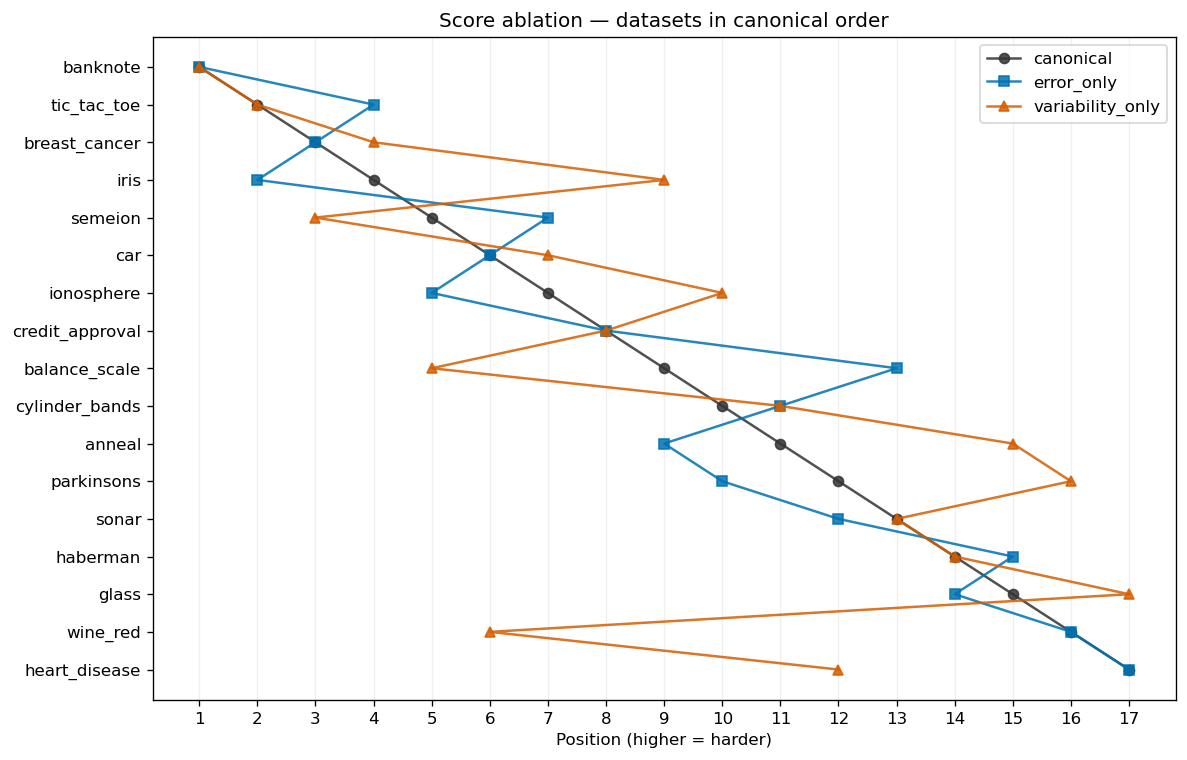

In [9]:
ablation = pd.concat([score_panel(canonical_components, variant, alpha) for variant, alpha in
    [('canonical', .70), ('error_only', 1.), ('variability_only', 0.)]], ignore_index=True)
export_table(ablation, 'ablation_long')
ablation_comparisons, ablation_summaries = [], []
for variant in ['error_only', 'variability_only']:
    detail, summary, transition = compare_panels(canonical, ablation[ablation.variant.eq(variant)])
    ablation_comparisons.append(detail)
    ablation_summaries.append(summary)
    export_table(transition, f'ablation_transition_{variant}', index=True)
export_table(pd.concat(ablation_comparisons, ignore_index=True), 'ablation_comparisons')
wide = canonical[['dataset', 'position', 'difficulty_group']].rename(columns={
    'position':'canonical_position', 'difficulty_group':'canonical_group'})
for detail in ablation_comparisons:
    variant = detail.variant_variant.iloc[0]
    columns = ['position_variant', 'difficulty_group_variant', 'position_delta', 'group_changed']
    wide = wide.merge(detail[['dataset'] + columns].rename(columns={c: variant + '_' + c for c in columns}), on='dataset')
export_table(wide, 'ablation_by_dataset')
display(export_table(pd.DataFrame(ablation_summaries), 'ablation_summary'))
canonical_order = canonical.sort_values('position').dataset.tolist()
fig, ax = plt.subplots(figsize=(10, max(5, .38 * len(pool))))
for variant, color, marker in [('canonical', '#333333','o'), ('error_only','#0072B2','s'), ('variability_only','#D55E00','^')]:
    values = ablation[ablation.variant.eq(variant)].set_index('dataset').loc[canonical_order]
    ax.plot(values.position, np.arange(len(pool)), marker=marker, color=color, label=variant, alpha=.85)
ax.set(yticks=np.arange(len(pool)), yticklabels=canonical_order, xlabel='Position (higher = harder)',
       xticks=np.arange(1, len(pool)+1), title='Score ablation — datasets in canonical order')
ax.invert_yaxis()
ax.grid(axis='x', alpha=.2)
ax.legend()
save_figure(fig, 'ablation_positions')

## Block 2 — Dependence on baseline models

**2A. Removing logistic regression.** Original DT-only reuses the two canonical trees, recomputes F, E and V, and normalizes using its own extrema on the fixed canonical pool.

**2B. Tree regularization.** Four prespecified settings are evaluated with both `class_weight=None` and `class_weight="balanced"`: leaf sizes 2 and 5 without pruning, and `ccp_alpha=0.001` and `0.01` with leaf size 1. All other `TREE_CONFIG` parameters are retained. Each panel contains exactly two trees and recomputes its own component normalization. These settings are a bounded sensitivity analysis, not an exhaustive search or optimal dataset-specific pruning. No setting is selected for agreement with the canonical ranking.

Failed configurations retain their errors and warnings and block the entire affected panel comparison, without shrinking the pool or changing its normalization extrema. This block evaluates sensitivity to the baselines; it does not demonstrate the utility of stratification.

CV seed 42: anneal completed; comparable=True
CV seed 42: balance_scale completed; comparable=True
CV seed 42: car completed; comparable=True
CV seed 42: cylinder_bands completed; comparable=True
CV seed 42: glass completed; comparable=True
CV seed 42: heart_disease completed; comparable=True
CV seed 42: ionosphere completed; comparable=True
CV seed 42: semeion completed; comparable=True
CV seed 42: sonar completed; comparable=True
CV seed 42: tic_tac_toe completed; comparable=True
CV seed 42: breast_cancer completed; comparable=True
CV seed 42: wine_red completed; comparable=True
CV seed 42: iris completed; comparable=True
CV seed 42: haberman completed; comparable=True
CV seed 42: parkinsons completed; comparable=True
CV seed 42: banknote completed; comparable=True
CV seed 42: credit_approval completed; comparable=True
characterization_cell_9:152: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the

,panel,model,ccp_alpha,class_weight,criterion,max_depth,max_features,max_leaf_nodes,min_impurity_decrease,min_samples_leaf,min_samples_split,min_weight_fraction_leaf,random_state,splitter
0,dt_original,decision_tree_default,0.000,None,gini,None,None,None,0.0,1,2,0.0,42,best
1,dt_original,decision_tree_balanced,0.000,balanced,gini,None,None,None,0.0,1,2,0.0,42,best
2,dt_leaf_2,decision_tree_leaf_2_default,0.000,None,gini,None,None,None,0.0,2,2,0.0,42,best
3,dt_leaf_2,decision_tree_leaf_2_balanced,0.000,balanced,gini,None,None,None,0.0,2,2,0.0,42,best
4,dt_leaf_5,decision_tree_leaf_5_default,0.000,None,gini,None,None,None,0.0,5,2,0.0,42,best
5,dt_leaf_5,decision_tree_leaf_5_balanced,0.000,balanced,gini,None,None,None,0.0,5,2,0.0,42,best
6,dt_ccp_001,decision_tree_ccp_001_default,0.001,None,gini,None,None,None,0.0,1,2,0.0,42,best
7,dt_ccp_001,decision_tree_ccp_001_balanced,0.001,balanced,gini,None,None,None,0.0,1,2,0.0,42,best
8,dt_ccp_01,decision_tree_ccp_01_default,0.010,None,gini,None,None,None,0.0,1,2,0.0,42,best
9,dt_ccp_01,decision_tree_ccp_01_balanced,0.010,balanced,gini,None,None,None,0.0,1,2,0.0,42,best


,reference,variant,n_datasets,spearman_rho,p_value,correlation_status,n_group_changes,proportion_group_changed,mean_absolute_position_delta,max_absolute_position_delta
0,canonical,dt_original,17,0.953431,3.284995e-09,ok,4,0.235294,1.058824,4
1,canonical,dt_leaf_2,17,0.933824,4.326327e-08,ok,4,0.235294,1.294118,4
2,canonical,dt_leaf_5,17,0.950980,4.791757e-09,ok,2,0.117647,1.058824,3
3,canonical,dt_ccp_001,17,0.963235,5.740995e-10,ok,2,0.117647,0.941176,3
4,canonical,dt_ccp_01,17,0.921569,1.492082e-07,ok,6,0.352941,1.529412,4
5,dt_original,canonical,17,0.953431,3.284995e-09,ok,4,0.235294,1.058824,4
6,dt_original,dt_leaf_2,17,0.977941,1.299146e-11,ok,0,0.000000,0.470588,3
7,dt_original,dt_leaf_5,17,0.982843,2.000914e-12,ok,2,0.117647,0.588235,2
8,dt_original,dt_ccp_001,17,0.997549,9.580348e-19,ok,2,0.117647,0.117647,1
9,dt_original,dt_ccp_01,17,0.948529,6.859595e-09,ok,2,0.117647,0.941176,5


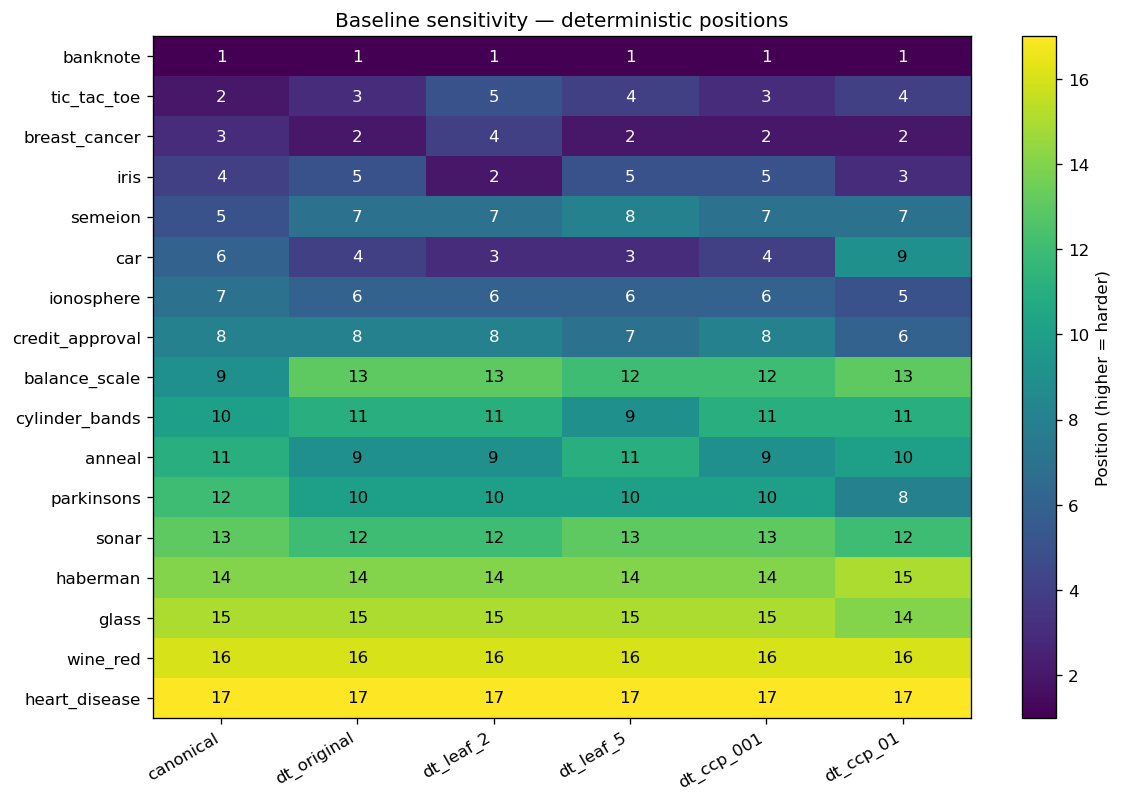

,panel,f1_macro_mean_delta_mean,f1_macro_mean_delta_median,f1_macro_mean_delta_min,f1_macro_mean_delta_max,mean_tree_nodes_delta_mean,mean_tree_nodes_delta_median,mean_tree_nodes_delta_min,mean_tree_nodes_delta_max,mean_tree_depth_delta_mean,mean_tree_depth_delta_median,mean_tree_depth_delta_min,mean_tree_depth_delta_max,mean_tree_leaves_delta_mean,mean_tree_leaves_delta_median,mean_tree_leaves_delta_min,mean_tree_leaves_delta_max
0,dt_ccp_001,-0.000944,0.000000,-0.009469,0.004699,-38.388235,-9.000000,-306.933333,0.000000,-0.605882,-0.100000,-3.133333,0.000000,-19.194118,-4.500000,-153.466667,0.000000
1,dt_ccp_01,-0.045019,-0.007845,-0.238583,0.040617,-141.866667,-103.666667,-696.000000,-4.400000,-5.854902,-5.000000,-16.200000,-0.500000,-70.933333,-51.833333,-348.000000,-2.200000
2,dt_leaf_2,-0.006222,-0.004312,-0.043929,0.023762,-33.666667,-16.066667,-142.200000,-2.666667,-1.058824,-1.066667,-2.233333,-0.200000,-16.833333,-8.033333,-71.100000,-1.333333
3,dt_leaf_5,-0.013368,-0.008497,-0.113898,0.030012,-82.545098,-54.000000,-379.133333,-4.800000,-2.803922,-2.866667,-6.133333,-0.433333,-41.272549,-27.000000,-189.566667,-2.400000
4,dt_original,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [10]:
TREE_SETTINGS = {'leaf_2': dict(min_samples_leaf=2, ccp_alpha=0.0),
                 'leaf_5': dict(min_samples_leaf=5, ccp_alpha=0.0),
                 'ccp_001': dict(min_samples_leaf=1, ccp_alpha=0.001),
                 'ccp_01': dict(min_samples_leaf=1, ccp_alpha=0.01)}
panel_models = {'dt_original': TREE_BASELINE_MODELS.copy()}
for setting, overrides in TREE_SETTINGS.items():
    names = []
    for weight in [None, 'balanced']:
        name = f"decision_tree_{setting}_{'default' if weight is None else 'balanced'}"
        MODEL_CONFIGS[name] = {**TREE_CONFIG, **overrides, 'class_weight': weight}
        names.append(name)
    panel_models['dt_' + setting] = names
new_models = [m for panel, models in panel_models.items() if panel != 'dt_original' for m in models]
configuration_rows = []
for panel, models in panel_models.items():
    for model in models:
        configuration_rows.append(dict(panel=panel, model=model, **DecisionTreeClassifier(**MODEL_CONFIGS[model]).get_params()))
configuration_table = export_table(pd.DataFrame(configuration_rows), 'tree_configurations')
display(configuration_table)
write_json(EXPERIMENT_ROOT / 'all_model_configurations.json', MODEL_CONFIGS)
sensitivity_df, sensitivity_audit_df = evaluate_baselines({d: loaded[d] for d in pool}, models=new_models)
experiment_store.export(sensitivity_df, 'tree_sensitivity')
export_table(sensitivity_audit_df, 'tree_sensitivity_cv_audit')
all_results = pd.concat([baseline_df, sensitivity_df], ignore_index=True)
performance_columns = ['dataset','model','f1_macro_mean','f1_macro_std','mean_tree_nodes',
                       'mean_tree_depth','mean_tree_leaves','warnings','error']
performance = all_results.loc[all_results.model.isin(configuration_table.model) & all_results.dataset.isin(pool), performance_columns].merge(
    configuration_table[['model','panel','class_weight','min_samples_leaf','ccp_alpha']], on='model', validate='many_to_one')
export_table(performance, 'tree_performance_complexity')
panels = {'canonical': canonical}
blocked = []
for panel, models in panel_models.items():
    try:
        panels[panel] = score_panel(panel_components(all_results, models), panel)
    except ValueError as exc:
        blocked.append(dict(panel=panel, error=str(exc)))
        print(f'BLOCKED PANEL {panel}: {exc}')
export_table(pd.DataFrame(blocked, columns=['panel', 'error']), 'blocked_panels')
export_table(pd.concat(panels.values(), ignore_index=True), 'baseline_panel_rankings')
panel_details, panel_summaries = [], []
for reference_name in ['canonical', 'dt_original']:
    if reference_name not in panels:
        continue
    for panel, values in panels.items():
        if panel == reference_name:
            continue
        detail, summary, transition = compare_panels(panels[reference_name], values)
        panel_details.append(detail)
        panel_summaries.append(summary)
        export_table(transition, f'transition_{reference_name}_to_{panel}', index=True)
export_table(pd.concat(panel_details, ignore_index=True) if panel_details else pd.DataFrame(), 'baseline_panel_comparisons')
display(export_table(pd.DataFrame(panel_summaries), 'baseline_panel_summary'))
positions = pd.DataFrame({key: value.set_index('dataset').position for key, value in panels.items()}).loc[canonical_order]
fig, ax = plt.subplots(figsize=(10, max(5, .4 * len(pool))))
im = ax.imshow(positions, cmap='viridis', vmin=1, vmax=len(pool), aspect='auto')
ax.set(xticks=range(len(positions.columns)), xticklabels=positions.columns,
       yticks=range(len(pool)), yticklabels=positions.index, title='Baseline sensitivity — deterministic positions')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for i in range(len(pool)):
    for j in range(len(positions.columns)):
        ax.text(j, i, str(int(positions.iloc[i,j])), ha='center', va='center',
                color='white' if positions.iloc[i,j] < len(pool)/2 else 'black')
fig.colorbar(im, ax=ax, label='Position (higher = harder)')
save_figure(fig, 'baseline_positions')

# Paired changes at the dataset/panel level; incomplete panels are omitted explicitly above.
metrics = ['f1_macro_mean','mean_tree_nodes','mean_tree_depth','mean_tree_leaves']
complete_performance = performance[performance.panel.isin(panels)]
panel_performance = complete_performance.groupby(['dataset','panel'])[metrics].mean().reset_index()
original_performance = panel_performance[panel_performance.panel.eq('dt_original')].drop(columns='panel')
deltas = panel_performance.merge(original_performance, on='dataset', suffixes=('', '_original'), validate='many_to_one')
for metric in metrics:
    deltas[metric + '_delta'] = deltas[metric] - deltas[metric + '_original']
export_table(deltas, 'performance_complexity_changes')
descriptive = deltas.groupby('panel')[[m+'_delta' for m in metrics]].agg(['mean','median','min','max'])
descriptive.columns = ['_'.join(c) for c in descriptive.columns]
display(export_table(descriptive.reset_index(), 'performance_complexity_summary'))

## Block 3 — Sample size and class structure

The observation unit is the **dataset**, never an individual CV fold. Metadata are calculated from `loaded` after missing targets have been removed and checked against `target_audit_df`. E and V remain unnormalized; D is the canonical score. All correlations use the full fixed canonical pool. Constant variables yield an explicitly undefined coefficient; non-finite values stop the analysis instead of silently dropping datasets.

These associations are exploratory. P-values are approximate and unadjusted for multiple comparisons; no significance stars or conclusions based only on p-values are used. Correlation does not identify causality, and the descriptors may themselves be related. These associations cannot replace controlled subsampling or learning curves. They cannot establish that V is exclusively sample size, or that it captures difficulty independently of sample size.

Completed exploratory analysis for 17 datasets; all numeric summaries derive from the evaluated results.


component,E,V,D
descriptor,,,
n_samples,-0.203431,-0.669118,-0.348039
min_class_count,-0.602941,-0.627451,-0.708333
n_classes,0.352399,0.055852,0.332452
imbalance_ratio,0.514706,0.311275,0.524510


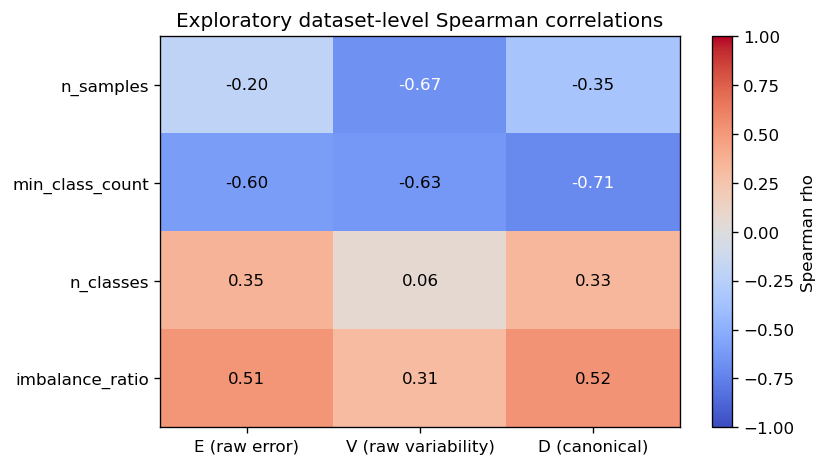

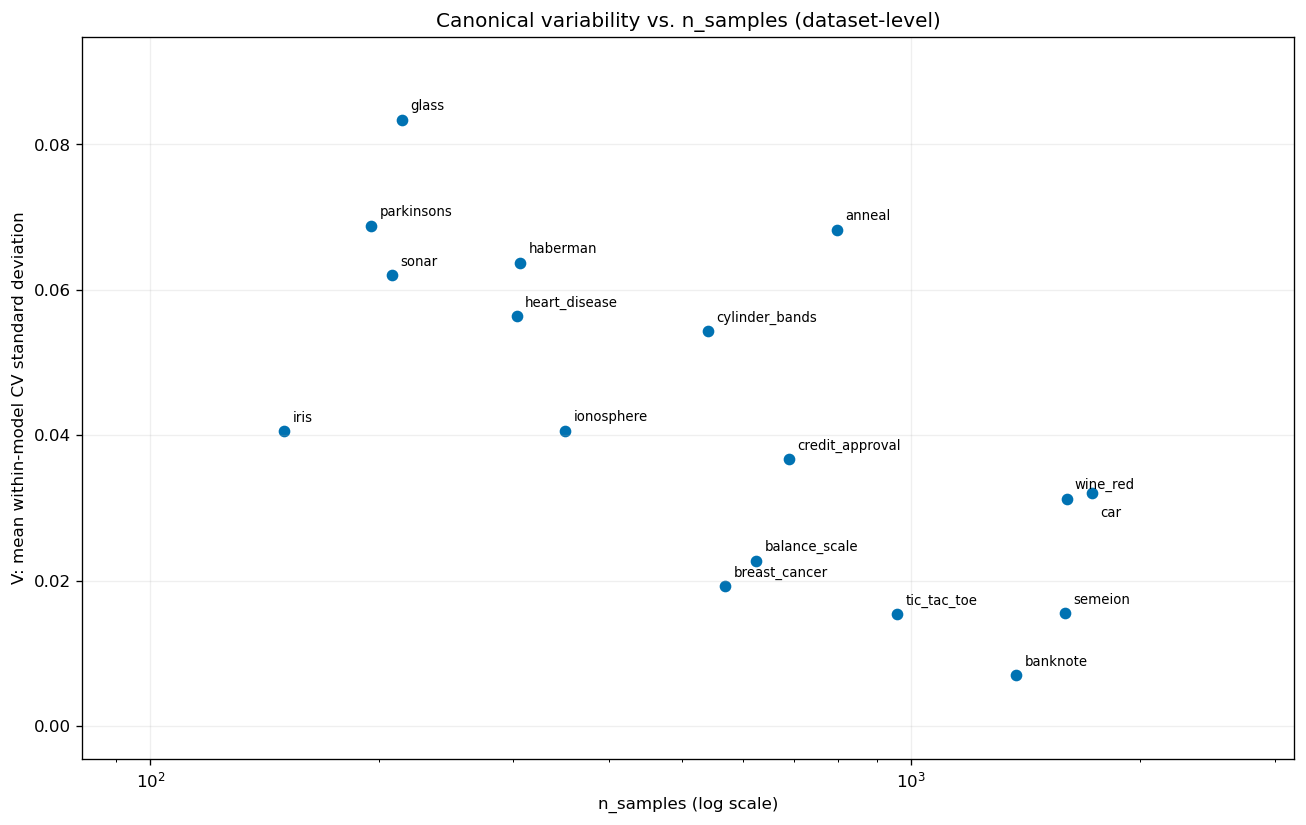

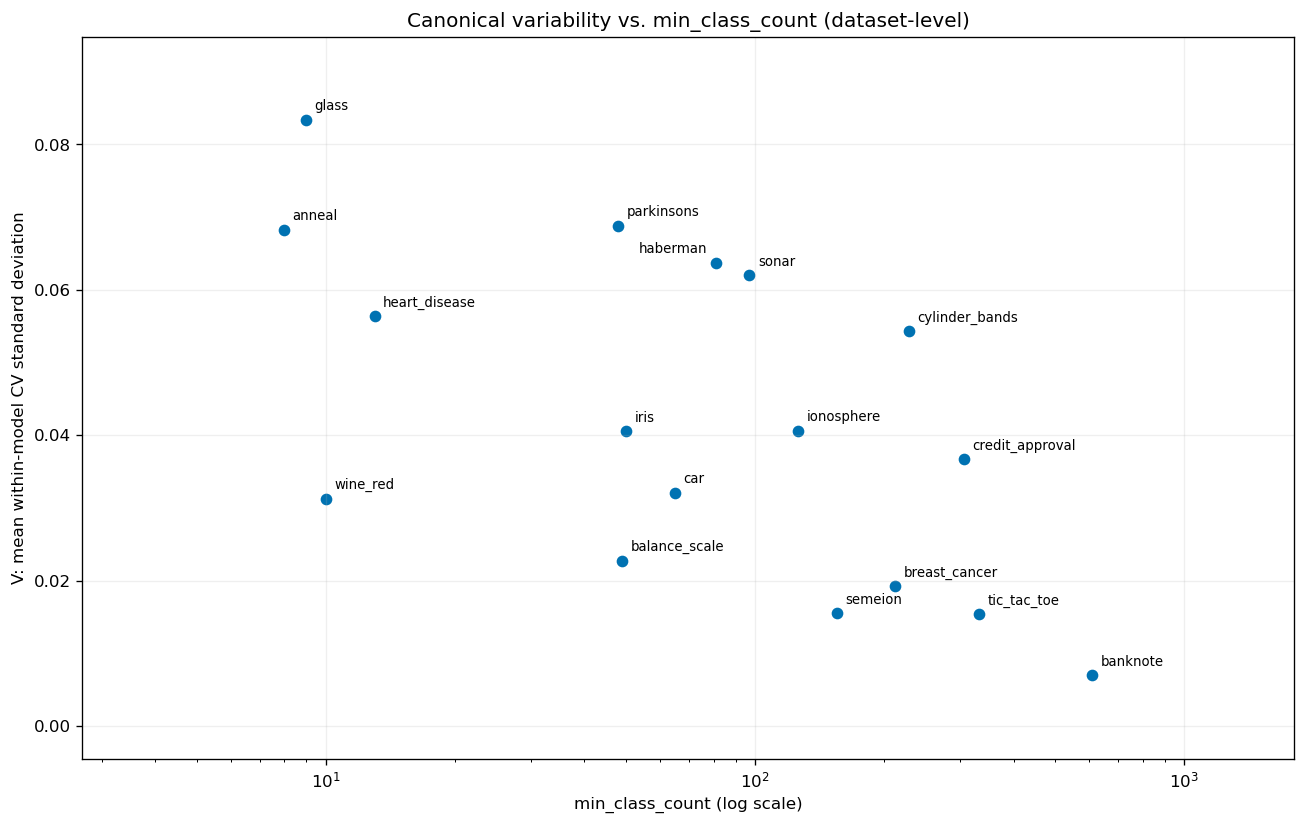

In [11]:
metadata_rows = []
audit_by_dataset = target_audit_df.set_index('dataset', verify_integrity=True)
for dataset in pool:
    obj = loaded[dataset]
    counts = obj['y_raw'].value_counts()
    row = dict(dataset=dataset, n_samples=len(obj['y_raw']), min_class_count=int(counts.min()),
               n_classes=len(counts), imbalance_ratio=float(counts.max()/counts.min()))
    assert len(obj['X']) == row['n_samples'] == len(obj['y'])
    for field in ['n_samples','min_class_count','n_classes']:
        assert row[field] == audit_by_dataset.loc[dataset, field], f'{dataset}: metadata mismatch for {field}'
    recorded_counts = json.loads(audit_by_dataset.loc[dataset, 'class_counts_raw'])
    assert recorded_counts == {str(k): int(v) for k, v in counts.items()}
    metadata_rows.append(row)
analysis_table = pd.DataFrame(metadata_rows).merge(canonical[['dataset','E','V','difficulty_score']].rename(
    columns={'E':'predictive_error','V':'cv_variability','difficulty_score':'predictive_difficulty_score'}), on='dataset', validate='one_to_one')
export_table(analysis_table, 'sample_class_analysis')
descriptors = ['n_samples','min_class_count','n_classes','imbalance_ratio']
components = ['predictive_error','cv_variability','predictive_difficulty_score']
correlations = []
for descriptor in descriptors:
    for component in components:
        rho, pvalue, status = safe_spearman(analysis_table[descriptor], analysis_table[component])
        correlations.append(dict(descriptor=descriptor, component=component, n_datasets=len(pool),
                                 spearman_rho=rho, p_value=pvalue, status=status))
correlation_table = export_table(pd.DataFrame(correlations), 'sample_class_spearman_long')
rho_table = correlation_table.pivot(index='descriptor', columns='component', values='spearman_rho').reindex(
    index=descriptors, columns=components).rename(columns=dict(zip(components, ['E','V','D'])))
display(export_table(rho_table, 'sample_class_spearman_rho', index=True))
fig, ax = plt.subplots(figsize=(7,4))
im = ax.imshow(rho_table, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
ax.set(xticks=range(3), xticklabels=['E (raw error)','V (raw variability)','D (canonical)'],
       yticks=range(4), yticklabels=descriptors, title='Exploratory dataset-level Spearman correlations')
for i in range(4):
    for j in range(3):
        value = rho_table.iloc[i,j]
        ax.text(j, i, f'{value:.2f}' if np.isfinite(value) else 'undefined', ha='center', va='center',
                color='white' if np.isfinite(value) and abs(value) > .65 else 'black')
fig.colorbar(im, ax=ax, label='Spearman rho')
save_figure(fig, 'sample_class_spearman')
for descriptor in ['n_samples', 'min_class_count']:
    fig, ax = plt.subplots(figsize=(11,7))
    ax.scatter(analysis_table[descriptor], analysis_table.cv_variability, color='#0072B2', marker='o')
    ax.set_xscale('log')
    ax.margins(x=.25, y=.15)
    ax.set(xlabel=f'{descriptor} (log scale)', ylabel='V: mean within-model CV standard deviation',
           title=f'Canonical variability vs. {descriptor} (dataset-level)')
    ax.grid(alpha=.2)
    annotate_scatter(ax, analysis_table, descriptor)
    save_figure(fig, f'variability_vs_{descriptor}')
print(f'Completed exploratory analysis for {len(pool)} datasets; all numeric summaries derive from the evaluated results.')